# MatPlotLib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../files/studietimmar_cleaned.csv")
sumclass = pd.read_csv("../files/summary_by_class.csv")


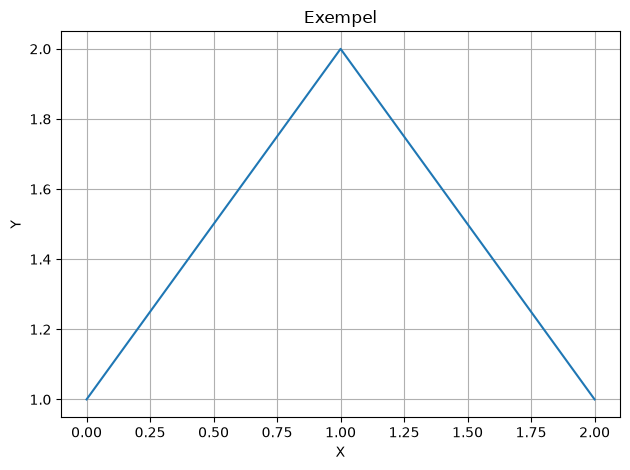

In [2]:
fig, ax = plt.subplots() # gives a figure and an axis
ax.plot([0, 1, 2],[1, 2, 1]) # list 1 is x-values list 2 is y-values
ax.set_title("Exempel")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(True)
plt.tight_layout() # gives a bit nicer margins

## Okabe ito colormap 
Customized order with yellow and black last

In [ ]:
okabe_ito= [
    '#E69F00',  # Orange
    '#56B4E9',  # Sky Blue
    '#D55E00',  # Vermillion
    '#009E73',  # Bluish Green
    '#CC79A7',  # Reddish Purple
    '#0072B2',  # Blue
    '#F0E442',  # Yellow
    '#000000'   # Black
]

#### Histogram with bins/intervals
- Saving the plot as file with savefig()

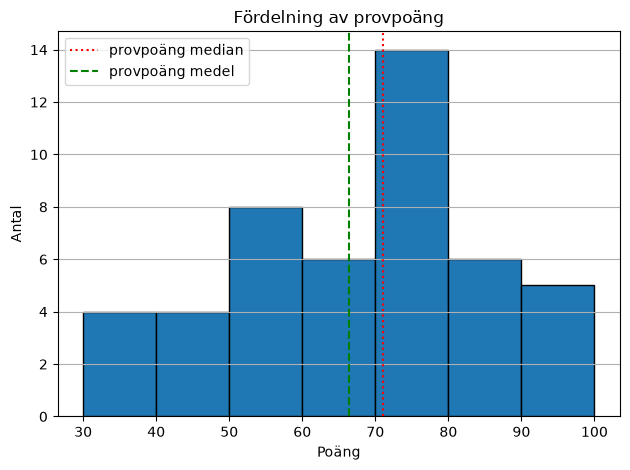

In [25]:
fig, ax = plt.subplots()
bins = [30,40,50,60,70,80,90,100]
ax.hist(df["provpoäng"].dropna(), bins=bins, edgecolor='black')
ax.set_title("Fördelning av provpoäng")
ax.set_xlabel("Poäng")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
plt.axvline(df['provpoäng'].median(),color='red', label='provpoäng median', linestyle=':')
plt.axvline(df['provpoäng'].mean(),color='green', label='provpoäng medel', linestyle='--')
plt.tight_layout()
plt.legend()
plt.savefig("../files/hist_provpoang.png", dpi=150)

#### Scatterplot

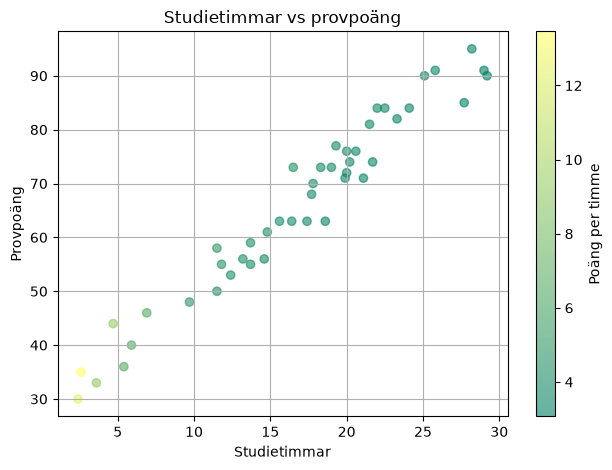

In [ ]:
fig, ax = plt.subplots()
scatter = ax.scatter(df["studietimmar"], df["provpoäng"], alpha=0.6, c=df['poang_per_timme'], cmap='summer')

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label('Poäng per timme')

ax.set_title("Studietimmar vs provpoäng")
ax.set_xlabel("Studietimmar")
ax.set_ylabel("Provpoäng")
ax.grid(True)
plt.tight_layout()

#### Bar chart with .setp()

[None, None, None, None]

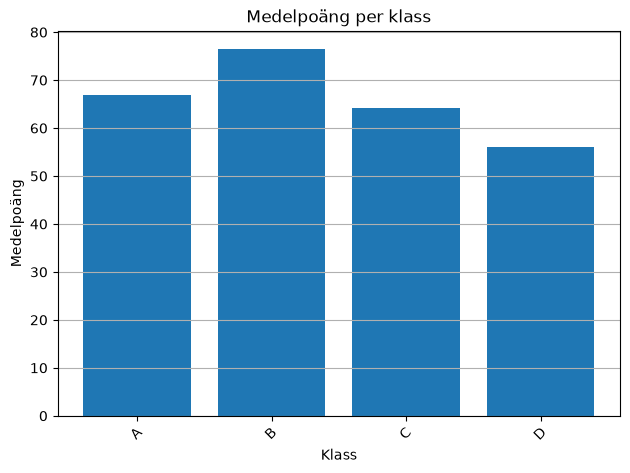

In [6]:
fig, ax = plt.subplots()
ax.bar(sumclass["klass"], sumclass["medel_poäng"])
ax.set_title("Medelpoäng per klass")
ax.set_xlabel("Klass")
ax.set_ylabel("Medelpoäng")
ax.grid(True, axis="y")
plt.tight_layout()
plt.setp(ax.get_xticklabels(), rotation=45) # rotates the xlabels 45 degrees

# Right diagram for datatype

- Distribution (1 numerical) : Histogram + boxplot
- Correlation (2 numericals) : Scatterplot, +linear model for regressive line
- Patterns ( 2 numericals) : Two barcharts side by side, normalized (0-1)
- Groups (category + numerical) : Groupby-table + bars and/or boxplots
- Shares/procents (category * category) : cut + crosstab(normalise='index')

### Pie chart

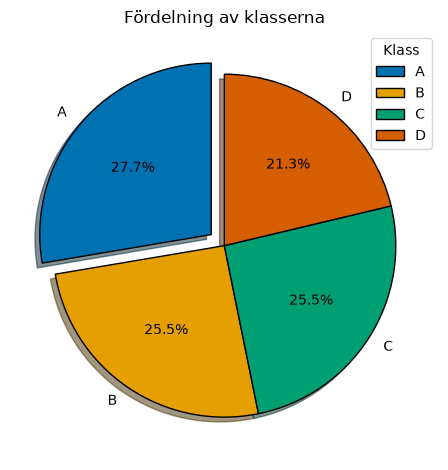

In [7]:
fig, ax = plt.subplots()

# explode makes the pie stand out from the rest, 0.1 = 10%
plt.pie(df['klass'].value_counts(), autopct='%1.1f%%', explode=[0.1, 0, 0, 0 ],
        shadow=True, startangle=90,
          wedgeprops={'edgecolor': 'black'}, labels=df['klass'].value_counts().index.sort_values(),
          colors=okabe_ito)

# .value_counts().index.sort_values() takes the indexes of valuecounts and sorts them .index is a property
ax.legend(labels=df['klass'].value_counts().index.sort_values() , title='Klass', loc='best')
plt.title('Fördelning av klasserna')
plt.tight_layout()
plt.show()


# Stack plot
good for data over time, no equivalent is in seaborn

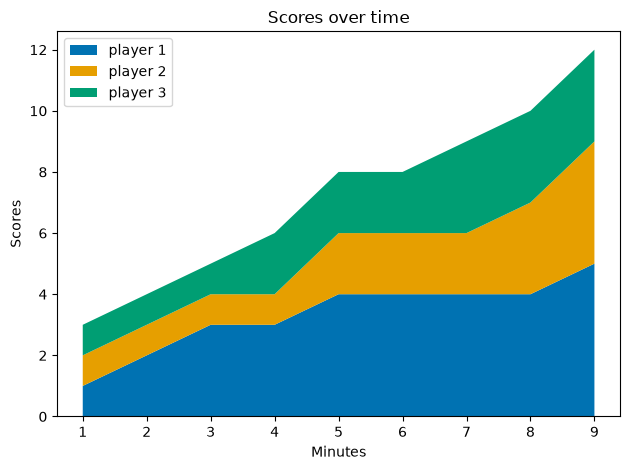

In [8]:
minutes = [1,2,3,4,5,6,7,8,9]
player1 = [1,2,3,3,4,4,4,4,5]
player2 = [1,1,1,1,2,2,2,3,4]
player3 = [1,1,1,2,2,2,3,3,3]

fig, ax = plt.subplots()
plt.stackplot(minutes, player1, player2, player3, colors = okabe_ito, labels=['player 1', 'player 2', 'player 3'])
plt.legend()
plt.title('Scores over time')
plt.xlabel('Minutes')
plt.ylabel('Scores')
plt.tight_layout()
plt.show()

### Filled area on Line plots
``` 
    ax.fill_between(df['x'], df['lower'], df['upper'], alpha=0.2)
```